# 实验5A：BERT 与 GPT-1 自注意力

In [1]:
EXPERIMENT='exp5A'
from pathlib import Path
import os, sys, random, json, time, copy, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
ROOT=Path.cwd() if (Path.cwd()/'exp5').is_dir() else Path.cwd().parent
BASE=ROOT/'exp5'; DATA=BASE/'data'; CACHE=BASE/'.cache'; RESULT=BASE/'results'/EXPERIMENT
for p in [DATA,CACHE,RESULT]: p.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(ROOT/'exp4/.cache/python'))
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'font.sans-serif':['Microsoft YaHei','SimHei','DejaVu Sans'],'axes.unicode_minus':False,'figure.dpi':110})
SENTENCE='今天终于通过了考试，我真的很开心！'
print(sys.executable,torch.__version__,device)
def savefig(name):
    plt.savefig(RESULT/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def metrics(y,p):
    pr,re,f,_=precision_recall_fscore_support(y,p,labels=[0,1,2],average='macro',zero_division=0)
    return dict(Accuracy=accuracy_score(y,p),Precision_macro=pr,Recall_macro=re,F1_macro=f)
def code_image(code):
    import textwrap
    code='\n'.join(part for line in code.splitlines() for part in (textwrap.wrap(line,width=110,subsequent_indent='    ',replace_whitespace=False) or ['']))
    fig,ax=plt.subplots(figsize=(13,max(3,len(code.splitlines())*.24))); ax.axis('off')
    ax.text(0,1,code,va='top',fontfamily=['Consolas','Microsoft YaHei'],fontsize=9,transform=ax.transAxes); savefig('model_code')


E:\CODE\DeepLearning-exp\.cache\exp5-env\Scripts\python.exe 2.14.1+cu130 cuda


In [2]:
# 缺少本地模型文件时，从指定官方模型仓库下载；以后复用缓存。
import requests
model_files={'google-bert/bert-base-chinese':['config.json','model.safetensors','vocab.txt','tokenizer_config.json','tokenizer.json'],
             'openai-community/openai-gpt':['config.json','model.safetensors','vocab.json','merges.txt','tokenizer_config.json','tokenizer.json']}
needed=list(model_files) if EXPERIMENT=='exp5A' else [list(model_files)[0 if EXPERIMENT=='exp5B' else 1]]
for repo in needed:
    directory=CACHE/repo.split('/')[-1];directory.mkdir(exist_ok=True)
    for filename in model_files[repo]:
        target=directory/filename
        if target.exists():continue
        response=requests.get(f'https://huggingface.co/{repo}/resolve/main/{filename}',stream=True,timeout=180);response.raise_for_status()
        temp=target.with_suffix(target.suffix+'.tmp')
        with temp.open('wb') as f:
            for chunk in response.iter_content(1024*1024):f.write(chunk)
        temp.replace(target)
print('模型文件就绪')


模型文件就绪


## 数据与解释边界
数据来自指定的 [Chinese Multi-Emotion Dialogue Dataset](https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset)。繁简转换、去重、排除冲突后分层划分70%/15%/15%；惊奇、关切等映射中性是实验约定，存在语境歧义。测试集只用于最终评价。注意力是权重分布，不能单独当成模型决策的因果解释。

In [3]:
import requests, re
from opencc import OpenCC
from sklearn.model_selection import train_test_split
raw=DATA/'emotion_raw.csv'
if not raw.exists():
    old=ROOT/'exp4/data/emotion_raw.csv'
    if old.exists(): raw.write_bytes(old.read_bytes())
    else:
        r=requests.get('https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset/resolve/main/data.csv',timeout=60);r.raise_for_status();raw.write_bytes(r.content)
cc=OpenCC('t2s'); df=pd.read_csv(raw).dropna(subset=['text','emotion'])
mapping={'开心语调':0,'悲伤语调':1,'愤怒语调':1,'厌恶语调':1,'平淡语气':2,'惊奇语调':2,'关切语调':2,'疑问语调':2}
names=['正面','负面','中性']
df['text_clean']=df.text.map(lambda s:re.sub(r'\s+','',cc.convert(s)))
df['label']=df.emotion.map(cc.convert).map(mapping)
assert df.label.notna().all(),df[df.label.isna()].emotion.unique()
conflict=df.groupby('text_clean').label.nunique(); df=df[~df.text_clean.isin(conflict[conflict>1].index)]
df=df[df.text_clean.str.len()>0].drop_duplicates('text_clean').reset_index(drop=True);df.label=df.label.astype(int)
tr,rest=train_test_split(np.arange(len(df)),test_size=.3,stratify=df.label,random_state=SEED)
va,te=train_test_split(rest,test_size=.5,stratify=df.loc[rest,'label'],random_state=SEED)
df['split']='train';df.loc[va,'split']='val';df.loc[te,'split']='test'
df.to_csv(RESULT/'data_split.csv',index=False,encoding='utf-8-sig')
pd.DataFrame([{'original':k,'target':names[v]} for k,v in mapping.items()]).to_csv(RESULT/'label_mapping.csv',index=False,encoding='utf-8-sig')
display(pd.crosstab(df.split,df.label).rename(columns=dict(enumerate(names))))


label,正面,负面,中性
split,,,
test,89,213,322
train,413,992,1502
val,89,212,322


## 指定预训练模型与中文适配
[BERT-base-chinese](https://huggingface.co/google-bert/bert-base-chinese) 与 [GPT-1](https://huggingface.co/openai-community/openai-gpt) 均为12层。GPT-1原为英语模型：保留原权重，扩展训练集中文字符和控制标记；新增嵌入随机初始化。因此第一部分的中文GPT图包含未训练字符嵌入的影响，不能将全部差异归因于结构。BERT按原分词，GPT逐字，跨模型不能逐格直接相减。

In [4]:
from transformers import BertTokenizer, BertForSequenceClassification
bt=BertTokenizer.from_pretrained(CACHE/'bert-base-chinese')
bert=BertForSequenceClassification.from_pretrained(CACHE/'bert-base-chinese',num_labels=3,attn_implementation='eager').to(device)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: E:\CODE\DeepLearning-exp\exp5\.cache\bert-base-chinese
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your do

In [5]:
from transformers import OpenAIGPTTokenizer, OpenAIGPTLMHeadModel
gt=OpenAIGPTTokenizer.from_pretrained(CACHE/'openai-gpt')
original_ids=gt.encode(SENTENCE)
print('原GPT词表的中文UNK比例:',sum(i==gt.unk_token_id for i in original_ids)/max(1,len(original_ids)))
# 只从训练文本建立新增字符词表；显式逐字编码，避免英语BPE丢失中文。
chars=sorted(set(''.join(df.loc[tr,'text_clean'])))
gt.add_tokens(chars);gt.add_special_tokens({'pad_token':'<pad>','bos_token':'<bos>','eos_token':'<eos>','sep_token':'<sentiment>','additional_special_tokens':['<positive>','<negative>','<neutral>']})
torch.manual_seed(SEED)
gpt=OpenAIGPTLMHeadModel.from_pretrained(CACHE/'openai-gpt',attn_implementation='eager')
gpt.resize_token_embeddings(len(gt),mean_resizing=False);gpt=gpt.to(device)
label_words=['<positive>','<negative>','<neutral>'];label_ids=[gt.convert_tokens_to_ids(x) for x in label_words]
assert all(len(gt.encode(x))==1 for x in label_words)
def prompt(text): return [gt.bos_token_id]+[gt.convert_tokens_to_ids(c) for c in text[:64]]+[gt.sep_token_id]
def gpt_sentence(text):
    ids=prompt(text);return torch.tensor([ids]),gt.convert_ids_to_tokens(ids)


原GPT词表的中文UNK比例: 1.0


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] OpenAIGPTLMHeadModel LOAD REPORT from: E:\CODE\DeepLearning-exp\exp5\.cache\openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [6]:
def attention_arrays(model,ids,mask=None):
    model.eval()
    with torch.no_grad():
        out=model(input_ids=ids.to(device),attention_mask=None if mask is None else mask.to(device),output_attentions=True)
    a=np.stack([x[0].float().cpu().numpy() for x in out.attentions])
    assert np.isfinite(a).all()
    return a

def attention_plot(a,tokens,title,filename):
    # 每层先对注意力头取均值；多层采用固定的线性深度权重，不是可训练权重，也不等于因果解释。
    per=a.mean(1); w=np.arange(1,len(per)+1,dtype=float);w/=w.sum()
    weighted=np.einsum('l,lij->ij',w,per)
    fig,axes=plt.subplots(1,4,figsize=(19,5),constrained_layout=True)
    for ax,m,label in zip(axes,[per[0],per[5],per[-1],weighted],['第1层','第6层','第12层','多层加权']):
        im=ax.imshow(m,cmap='viridis',vmin=0,vmax=max(float(per.max()),.1))
        ax.set_xticks(range(len(tokens)),tokens,rotation=90,fontsize=6);ax.set_yticks(range(len(tokens)),tokens,fontsize=6)
        ax.set(title=title+' '+label,xlabel='被关注位置 Key',ylabel='查询位置 Query')
    fig.colorbar(im,ax=axes,shrink=.65);savefig(filename)
    np.savez_compressed(RESULT/(filename+'.npz'),attention=a,layer_weights=w,tokens=np.array(tokens))
    return weighted

def compare_attention(before,after,tokens,title):
    b=before.mean(1);a=after.mean(1);w=np.arange(1,13)/78
    mats=[np.einsum('l,lij->ij',w,x) for x in [b,a]]
    fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
    for ax,m,label in zip(axes,[*mats,mats[1]-mats[0]],['训练前','训练后','变化（后－前）']):
        limit=max(abs(mats[1]-mats[0]).max(),1e-8)
        im=ax.imshow(m,cmap='coolwarm' if '变化' in label else 'viridis',vmin=-limit if '变化' in label else 0,vmax=limit if '变化' in label else max(x.max() for x in mats))
        ax.set_xticks(range(len(tokens)),tokens,rotation=90,fontsize=6);ax.set_yticks(range(len(tokens)),tokens,fontsize=6);ax.set_title(title+label);fig.colorbar(im,ax=ax,shrink=.7)
    savefig('attention_before_after')


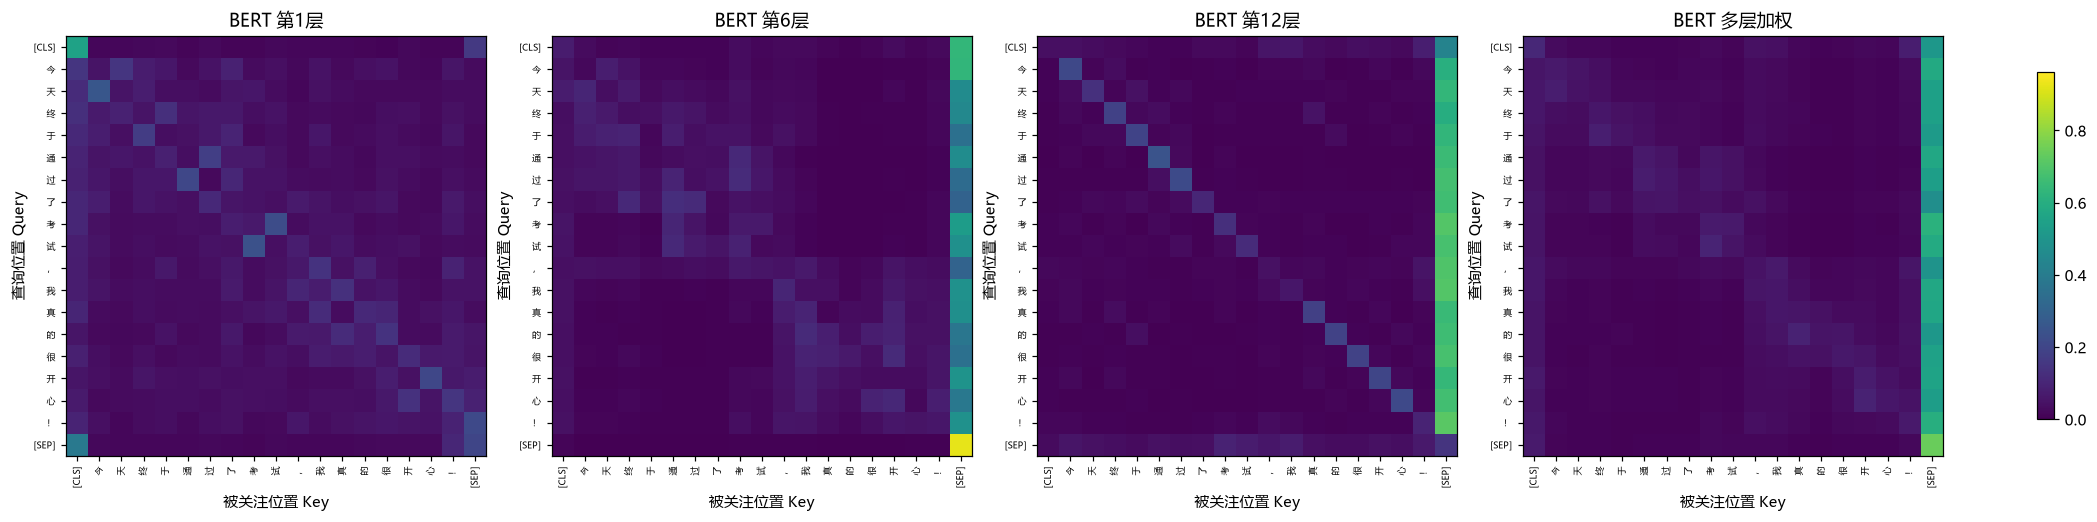

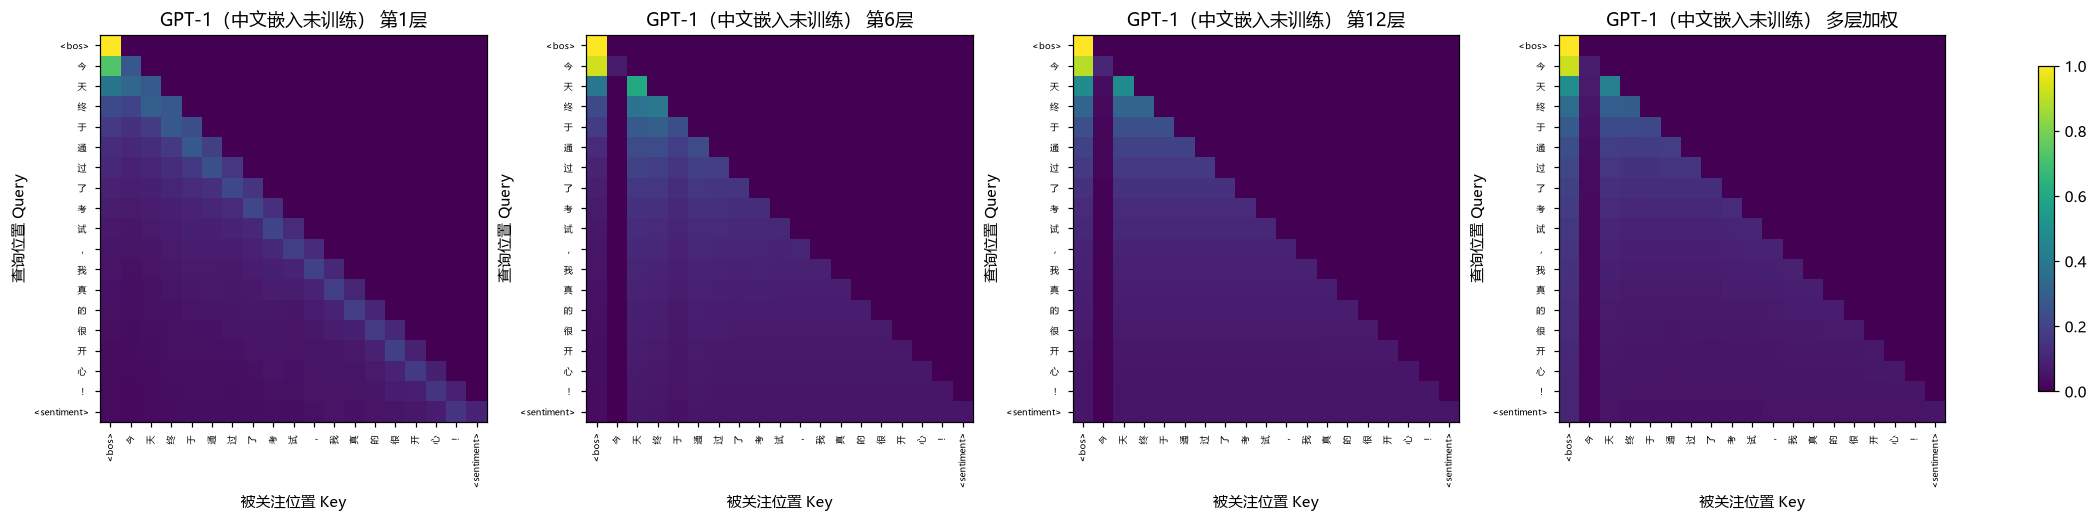

,model,layer,future_attention,entropy
0,BERT,1,0.432936,2.676186
1,BERT,2,0.312484,2.165500
2,BERT,3,0.293339,2.076176
3,BERT,4,0.551304,2.299003
4,BERT,5,0.658242,2.036098
5,BERT,6,0.624164,1.983689
6,BERT,7,0.694280,1.692036
7,BERT,8,0.751814,1.488670
8,BERT,9,0.757427,1.530606
9,BERT,10,0.777462,1.527809


GPT因果掩码核验通过；句子： 今天终于通过了考试，我真的很开心！


In [7]:
bi=bt(SENTENCE,return_tensors='pt'); bids=bi.input_ids; btoken=bt.convert_ids_to_tokens(bids[0]);gids,gtoken=gpt_sentence(SENTENCE)
ba=attention_arrays(bert,bids);ga=attention_arrays(gpt,gids)
attention_plot(ba,btoken,'BERT','bert_attention');attention_plot(ga,gtoken,'GPT-1（中文嵌入未训练）','gpt_attention')
rows=[]
for model,a in [('BERT',ba),('GPT-1',ga)]:
    for layer,m in enumerate(a.mean(1),1):
        rows.append(dict(model=model,layer=layer,future_attention=float(np.triu(m,1).sum()/len(m)),entropy=float(-(m*np.log(m+1e-12)).sum(1).mean())))
pd.DataFrame(rows).to_csv(RESULT/'attention_statistics.csv',index=False);display(pd.DataFrame(rows))
assert np.max(np.triu(ga.mean(1),1))<1e-6
print('GPT因果掩码核验通过；句子：',SENTENCE)
del bert,gpt;gc.collect();torch.cuda.empty_cache()
